# <b>Synthetic liquidation features for ETH toxic-flow filtering.</b>

This notebook investigates whether features generated using a conditional diffusion model can improve the out-of-sample filter for toxic maker flow on ETH.

The base model is `lgbm_huber`, trained on the `top 10 features` from the best ETH run. These features primarily describe recent liquidation flow, signed liquidation pressure, realised volatility, VPIN and time-of-day effects.

A set of `synthetic features` derived from the `diffusion model` is added to the baseline model. The diffusion model is `trained solely on the train portion`  of each walk-forward window and generates possible future liquidation paths. Features for tail liquidation risk are then constructed from these synthetic paths:

- diff2ch_p90_dollar_liq_30s
- diff2ch_p95_dollar_liq_30s
- diff2ch_p90_dollar_liq_120s
- diff2ch_p95_dollar_liq_120s
- diff2ch_p90_dollar_liq_300s
- diff2ch_p95_dollar_liq_300s

It is important to note that synthetic forecasts are `not generated for every trade or every liquidation event`. To save time, the forecast is based only on a selected grid of forecast anchors, after which the features are linked to the trades via the last available forecast. As a result, some trades receive an out-of-date forecast, and in certain periods the synthetic features become sparse and less locally informative.

Therefore, this experiment is not the final production version of the diffusion pipeline, but an initial test of the hypothesis:
“Does the forecast of the distribution of future liquidations contain an additional signal for PnL-based toxic-flow filtering?”


## <b>Imports.</b>

In [ ]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd() / "src"))

from experiment import (
    WalkForwardConfig,
    walk_forward
)
from splits import get_window_ids
import utilities as util

In [ ]:
import warnings

warnings.filterwarnings(
    "ignore",
    message=r"X does not have valid feature names, but LGBMRegressor was fitted with feature names",
    category=UserWarning
)

## <b>0. Config.</b>

In [ ]:
INSTRUMENT = "eth"
MODEL_NAME = "lgbm_huber"
HORIZONS = [30, 120, 300]

MAX_FILTER_RATES = [0.99, 0.995, 0.999]
FOCUS_FILTER_RATE = 0.999

# Grab features with synthetic data.
SPLIT_DIR = Path(f"data/meta/{INSTRUMENT}_splits_diff2ch")

# Top 10 features from file 3.ETH_Results.ipunb.
BASE_FEATURES = [
    "hour",
    "rv_120s",
    "signed_liq_binance_120s",
    "liq_bybit_120s",
    "signed_liq_bybit_120s",
    "liq_aligned_5s",
    "vpin_120s",
    "liq_binance_120s",
    "liq_aligned_30s",
    "liq_binance_30s"
]

DIFF = [
    "diff2ch_p90_dollar_liq_30s",
    "diff2ch_p95_dollar_liq_30s",
    "diff2ch_p90_dollar_liq_120s",
    "diff2ch_p95_dollar_liq_120s",
    "diff2ch_p90_dollar_liq_300s",
    "diff2ch_p95_dollar_liq_300s"
]

print("SPLIT_DIR:", SPLIT_DIR)
print("exists:", SPLIT_DIR.exists())
print(f"Base features ({len(BASE_FEATURES)}): {BASE_FEATURES}")

SPLIT_DIR: data\meta\eth_splits_diff2ch
exists: True
Base features (10): ['hour', 'rv_120s', 'signed_liq_binance_120s', 'liq_bybit_120s', 'signed_liq_bybit_120s', 'liq_aligned_5s', 'vpin_120s', 'liq_binance_120s', 'liq_aligned_30s', 'liq_binance_30s']


## <b>1. Walk-Forward.<b>

In [5]:
feature_variants = {
    "base": BASE_FEATURES,
    "diff_all": BASE_FEATURES + DIFF
}

results_ablation = {}

for tau in HORIZONS:
    for variant, feat_list in feature_variants.items():
        print(f"{INSTRUMENT.upper()} | {MODEL_NAME} | {variant} | tau={tau}s")

        config = WalkForwardConfig(
            instrument       = INSTRUMENT,
            tau              = tau,
            model_name       = MODEL_NAME,
            max_filter_rates = MAX_FILTER_RATES,
            window_ids       = get_window_ids(),
            verbose          = False,
            use_tqdm         = True
        )

        results_ablation[(variant, tau)] = walk_forward(
            config    = config,
            features  = feat_list,
            split_dir = SPLIT_DIR
        )

ETH | lgbm_huber | base | tau=30s


WF eth lgbm_huber tau=30s:   0%|          | 0/5 [00:00<?, ?it/s]

ETH | lgbm_huber | diff_all | tau=30s


WF eth lgbm_huber tau=30s:   0%|          | 0/5 [00:00<?, ?it/s]

ETH | lgbm_huber | base | tau=120s


...

WF eth lgbm_huber tau=120s:   0%|          | 0/5 [00:00<?, ?it/s]

ETH | lgbm_huber | base | tau=300s


WF eth lgbm_huber tau=300s:   0%|          | 0/5 [00:00<?, ?it/s]

ETH | lgbm_huber | diff_all | tau=300s


WF eth lgbm_huber tau=300s:   0%|          | 0/5 [00:00<?, ?it/s]

## <b>2. Summary tables.</b>

In [ ]:
summary_ablation = util.build_wf_summary_table(
    results         = results_ablation,
    max_filter_rate = FOCUS_FILTER_RATE
)

summary_ablation

,variant,tau,window,max_filter_rate,pnl_all,pnl_kept,pnl_filtered,score,"kept_turnover_per_day, mln$",turnover_ok,filter_rate
0,base,30,W1,0.999,-0.017476,3.111484,-0.204479,3.128960,14.77,True,0.9650
1,base,30,W2,0.999,-0.098579,-4.099585,-0.033140,-4.001006,4.43,True,0.9920
2,base,30,W3,0.999,-0.109866,7.926654,-0.175972,8.036520,1.92,True,0.9961
3,base,30,W4,0.999,-0.123401,-1.960672,-0.105114,-1.837271,2.50,True,0.9947
4,base,30,W5,0.999,-0.110326,-0.110326,0.000000,0.000000,211.02,True,0.0000
5,base,120,W1,0.999,0.168486,2.553203,-0.231559,2.384718,37.62,True,0.8935
6,base,120,W2,0.999,0.124330,9.258235,-0.441753,9.133904,16.07,True,0.9628
7,base,120,W3,0.999,-0.006987,5.033564,-0.022513,5.040550,0.72,True,0.9986
8,base,120,W4,0.999,-0.249273,22.955205,-0.476579,23.204478,2.46,True,0.9946
9,base,120,W5,0.999,-0.018461,5.538325,-0.151931,5.556787,4.95,True,0.9846


## <b>3. Chart with Scores.</b>

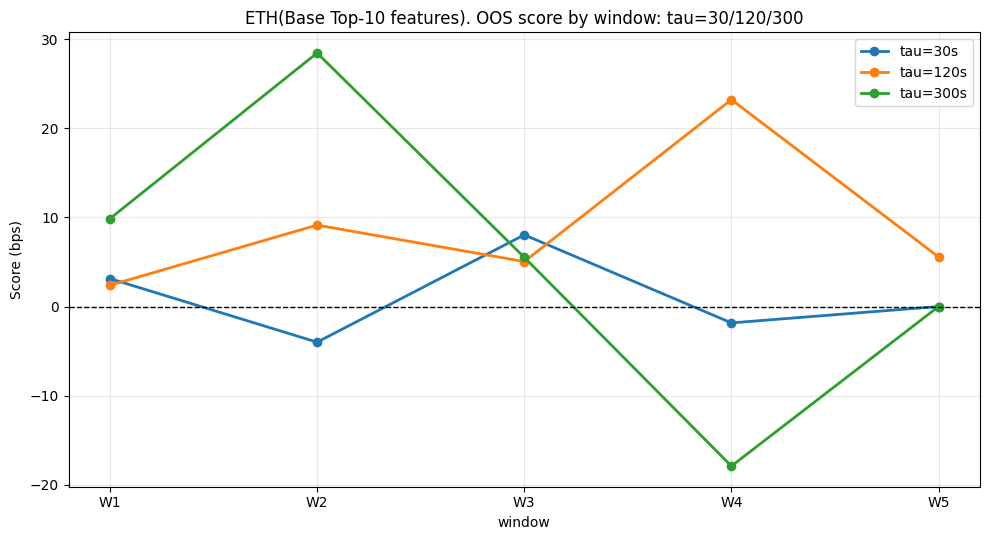

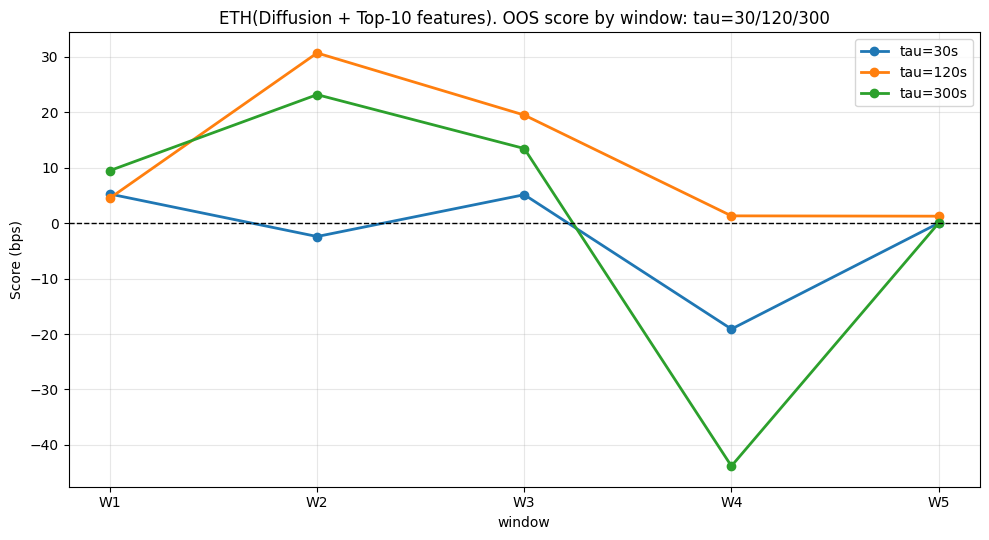

In [ ]:
pivot_scores_base = util.plot_score_by_window_one_chart(
    summary_table       = summary_ablation,
    variant             = "base",
    taus                = (30, 120, 300),
    title               = "ETH(Base Top-10 features). OOS score by window: tau=30/120/300"
)

pivot_scores_diff = util.plot_score_by_window_one_chart(
    summary_table       = summary_ablation,
    variant             = "diff_all",
    taus                = (30, 120, 300),
    title               = "ETH(Diffusion + Top-10 features). OOS score by window: tau=30/120/300"
)

## <b>4. Distribution charts.</b>

ETH_lgbm_huber_base_tau120s_fr0.999
Daily Score:
  mean   = +6.849223
  std    = 18.540475
  median = +3.839798
  min    = -47.818809
  max    = +88.498753
  >0 days: 76/105 (72%)
  <0 days: 29/105 (28%)

ETH_lgbm_huber_base_tau120s_fr0.999
Daily PnL kept:
  mean   = +6.833343
  std    = 18.565619
  median = +4.039471
  min    = -48.626330
  max    = +84.755337
  >0 days: 76/105 (72%)
  <0 days: 29/105 (28%)



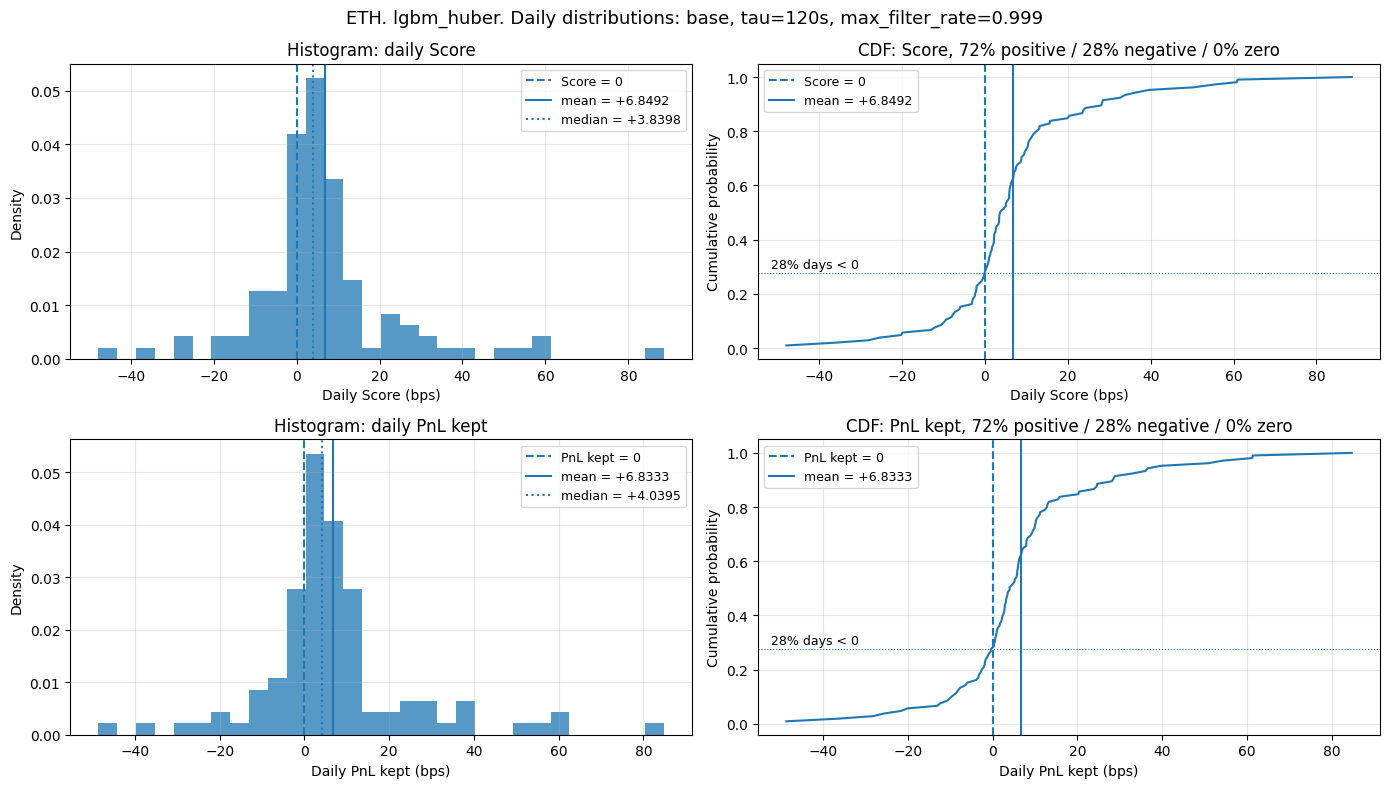

ETH_lgbm_huber_diff_all_tau120s_fr0.999
Daily Score:
  mean   = +7.305162
  std    = 20.154432
  median = +4.060261
  min    = -67.513108
  max    = +83.030761
  >0 days: 72/96 (75%)
  <0 days: 24/96 (25%)

ETH_lgbm_huber_diff_all_tau120s_fr0.999
Daily PnL kept:
  mean   = +7.281843
  std    = 20.375588
  median = +4.094849
  min    = -67.597740
  max    = +85.381623
  >0 days: 72/96 (75%)
  <0 days: 24/96 (25%)



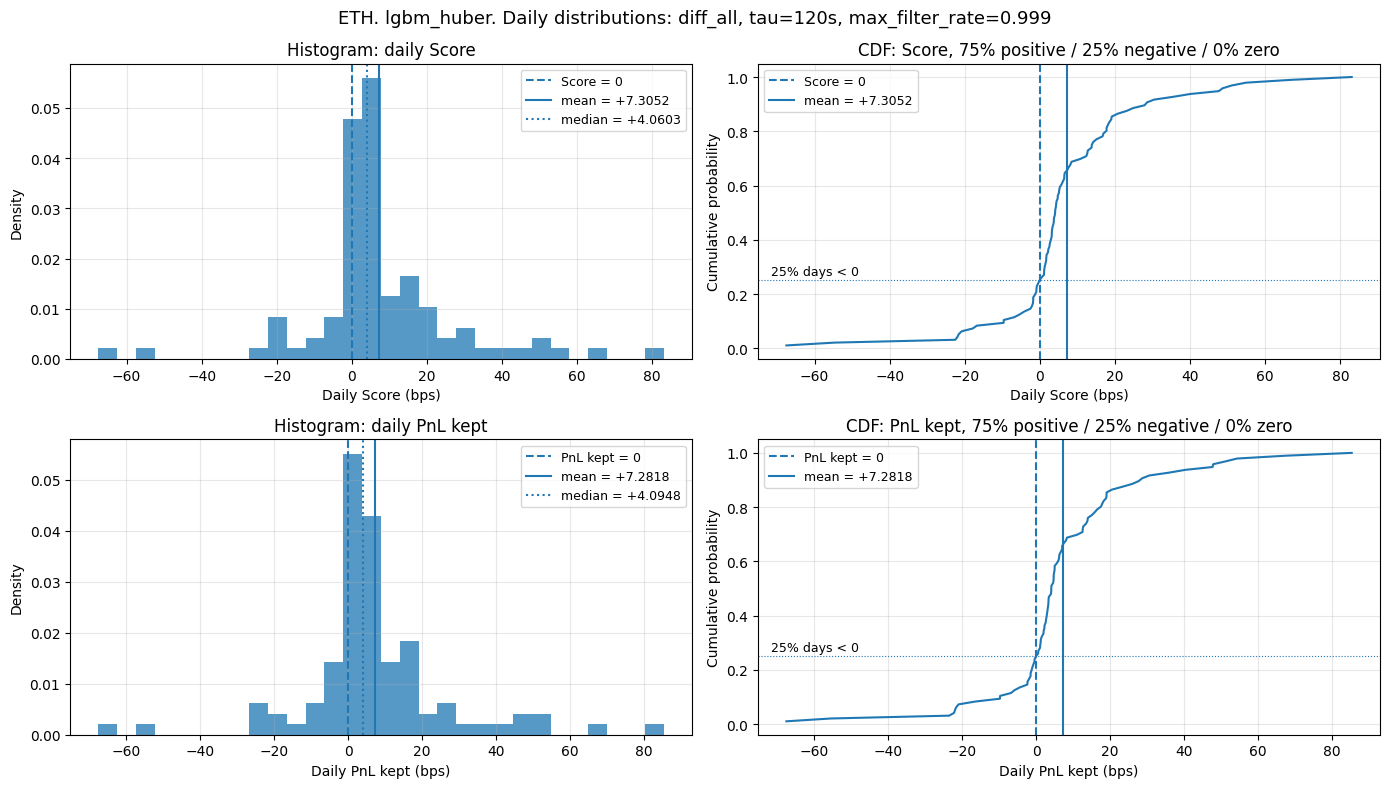

In [ ]:
daily = util.plot_daily_score_distribution(
    results         = results_ablation,
    variant         = "base",
    tau             = 120,
    max_filter_rate = FOCUS_FILTER_RATE,
    instrument      = INSTRUMENT,
    model_name      = MODEL_NAME
)

daily = util.plot_daily_score_distribution(
    results         = results_ablation,
    variant         = "diff_all",
    tau             = 120,
    max_filter_rate = FOCUS_FILTER_RATE,
    instrument      = INSTRUMENT,
    model_name      = MODEL_NAME
)


## <b>5. Feature importance.</b>

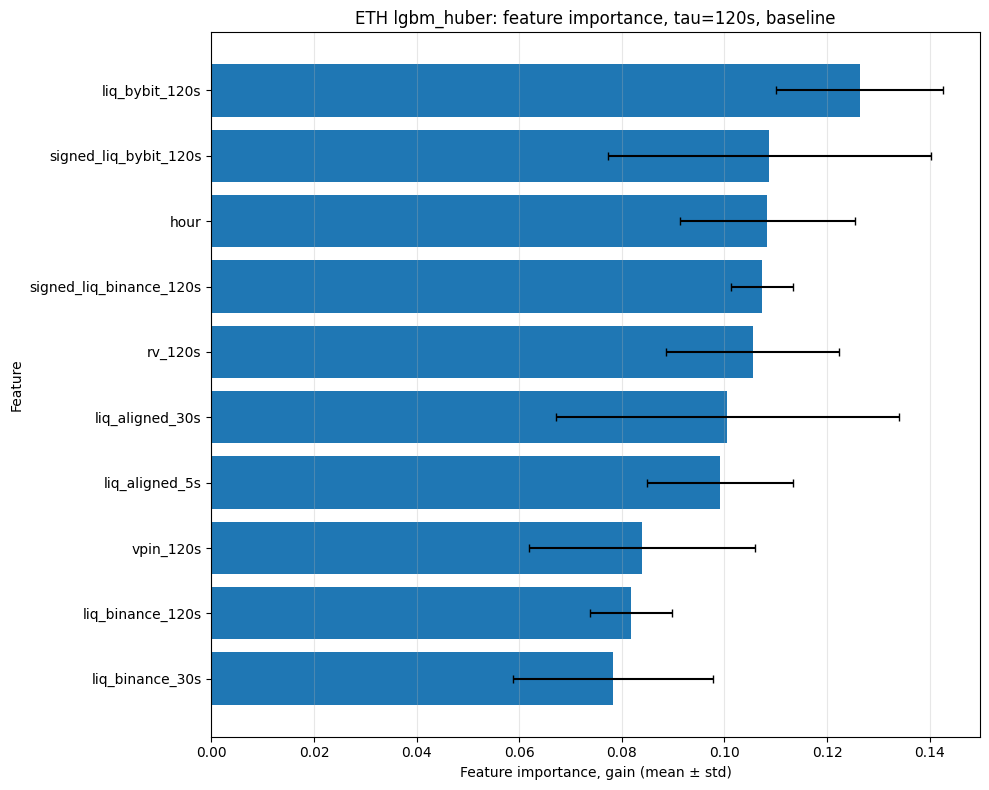

,feature,mean_importance,std_importance,n_models,sem_importance,interval
5,liq_bybit_120s,0.126366,0.016296,5,0.007288,0.016296
8,signed_liq_bybit_120s,0.108737,0.031482,5,0.014079,0.031482
0,hour,0.108323,0.017064,5,0.007631,0.017064
7,signed_liq_binance_120s,0.107378,0.006065,5,0.002712,0.006065
6,rv_120s,0.105502,0.016909,5,0.007562,0.016909
1,liq_aligned_30s,0.100551,0.033425,5,0.014948,0.033425
2,liq_aligned_5s,0.099148,0.014198,5,0.006350,0.014198
9,vpin_120s,0.083926,0.022020,5,0.009847,0.022020
3,liq_binance_120s,0.081778,0.008008,5,0.003581,0.008008
4,liq_binance_30s,0.078290,0.019546,5,0.008741,0.019546


In [ ]:
tau = 120
variant = "base"
result = results_ablation[("base", tau)]

fi = util.plot_lgbm_feature_importance(
    models              = result.models,
    top_n              = 30,
    importance_type    = "gain",
    interval           = "std",
    normalize_per_model= True,
    figsize            = (10, 8),
    title              = f"{INSTRUMENT.upper()} {MODEL_NAME}: feature importance, tau={tau}s, {variant}",
)

display(fi.head(30))

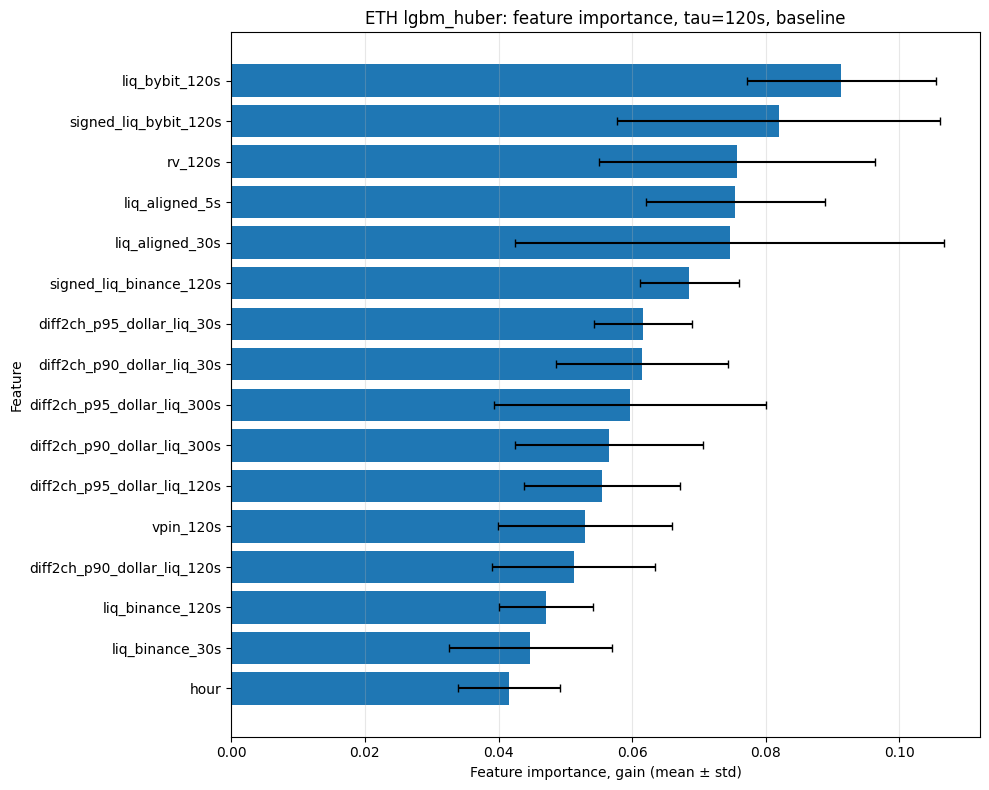

,feature,mean_importance,std_importance,n_models,sem_importance,interval
11,liq_bybit_120s,0.091314,0.014096,5,0.006304,0.014096
14,signed_liq_bybit_120s,0.081930,0.024155,5,0.010802,0.024155
12,rv_120s,0.075749,0.020668,5,0.009243,0.020668
8,liq_aligned_5s,0.075445,0.013441,5,0.006011,0.013441
7,liq_aligned_30s,0.074600,0.032123,5,0.014366,0.032123
13,signed_liq_binance_120s,0.068563,0.007458,5,0.003336,0.007458
5,diff2ch_p95_dollar_liq_30s,0.061570,0.007353,5,0.003288,0.007353
2,diff2ch_p90_dollar_liq_30s,0.061423,0.012881,5,0.005760,0.012881
4,diff2ch_p95_dollar_liq_300s,0.059747,0.020357,5,0.009104,0.020357
1,diff2ch_p90_dollar_liq_300s,0.056554,0.014067,5,0.006291,0.014067


In [ ]:
tau = 120
variant = "diff_all"

result = results_ablation[("diff_all", tau)]

fi = util.plot_lgbm_feature_importance(
    models              = result.models,
    top_n              = 30,
    importance_type    = "gain",
    interval           = "std",
    normalize_per_model= True,
    figsize            = (10, 8),
    title              = f"{INSTRUMENT.upper()} {MODEL_NAME}: feature importance, tau={tau}s, {variant}",
)

display(fi.head(30))


---
## <b>Executive summary.</b>

The experiment compares two configurations:

- `base` – the top 10 features from the best ETH run;
- `diff_all` – the same top 10 features plus 6 synthetic liquidation features derived from a conditional diffusion model.

All results below are given for `max_filter_rate = 0.999`.

### Base model results

The base model shows the best and most consistent performance over the horizon

$$
\tau = 120s.
$$

The following Score values were obtained for `base`:

tau = 30s:
mean: +1.07 bps

tau = 120s:
mean: +9.06 bps

tau = 300s:
mean: +5.18 bps

The following Score values were obtained for `base + diffusion`:

tau = 30s:
mean: -2.22 bps

tau = 120s:
mean: +11.46 bps

tau = 300s:
mean: +0.47 bps

The strongest result is again obtained at a time horizon of tau=120s. However, the improvement is uneven; the features contain a useful signal, but it is unstable.

## <b>A key limitation of the current experiment</b> 

relates to how synthetic features are generated.

The diffusion model does `not generate a forecast for every trade`. Instead, a forecast is generated `only at selected anchor points`. After that, the latest available forecast is applied to the trades using ‘as-of’ logic.

This gives rise to three problems:

1. **Forecast sparsity.**
    - Synthetic features are not available at every point in time as a fresh forecast. Between anchor points, many trades may receive identical diffusion features.
2. **Forecast staleness.**
    - If the most recent forecast point was a long time ago, the features no longer describe the future relative to the current trade, but rather the future relative to an old liquidation anchor. This is particularly critical for long time horizons.
3. **Information degradation.**
    - With this approach, some local information is lost. Instead of an accurate conditional forecast for a specific point in time, the model obtains a coarser, regime-like characterisation.

This explains the deterioration observed on W4 and W5. On W1–W3, synthetic features yield a significant improvement at 120s, but the quality then declines